# 阶段 1：背景、模型假设与研究空白

> **阶段定位**：第 1–2 周｜回答「为什么难、别人怎么做、我该拿什么当输入」。
> **对应交卷**：[阶段1-文献解读与过关清单.md](../01-阶段一/阶段1-文献解读与过关清单.md) 的五件产物（现状综述 / 信号与噪声模型 / 文献卡片 / E1-E3 获取记录 / 问题清单）。
> **与 0 号的关系**：`0.ipynb` 是阶段 2–6 的完整复现预览；本号只做**阶段 1**，把纸面假设变成可运行、可复核的数字与图。
>
> **本号的边界（重要）**：
> - 做：文献格局、信号模型、噪声模型（白噪 + $1/f^\alpha$）、SNR 口径与反算、$H_0/H_1$ 假设检验框架、研究空白。
> - **不做**：Duffing 方程与势函数推导、RK4、相图与阈值曲线、$\lambda_c$ 数值、参数估计公式、FPGA 资源评估——那些属于阶段 2–5。
>
> **纪律**：每个数字后面跟条件（频段 / 带宽 / 噪声类型 / 判据）；不同论文的 SNR 口径**不可横向比较**。

In [1]:
# 环境、全局参数、绘图设置（与 learn/0.ipynb 同款）
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

def find_root():
    """notebook 可能在项目根（run_ipynb.py 默认）或 learn/ 下运行，向上找阶段 1 文档。"""
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / '阶段1-信号与噪声模型假设.md').is_file():
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

# ---- 阶段 1 初设参数（来自 阶段1-信号与噪声模型假设.md §四，逐行待导师替换）----
GAMMA_NT   = 1.0                    # 默认幅值 1 nT（范围 0.1–10 nT）
F_GRID     = (0.1, 1.0, 10.0)       # 信号频率三点（Hz），覆盖低噪声窗口两端
F_MAIN     = 1.0                    # 演示用主频（Hz）
THETA_DEG  = 40.0                   # 初相（°），未知量，这里仅用于造数据
FS         = 1000.0                 # 仿真采样率（Hz）
T_OBS      = 300.0                  # 观测时长（s），与阈值扫描档对齐
B_BAND     = 10.0                   # 带限带宽（Hz），窄带口径用
ALPHAS     = (0.5, 1.0, 1.2, 1.5)   # 1/f^alpha 四档，与 Sun 等仿真对齐
SEED       = 20261123
_START = time.time()

print(f'ROOT = {ROOT}')
print(f'采样率 {FS:.0f} Hz | 时长 {T_OBS:.0f} s | 样本数 {int(T_OBS * FS)} | '
      f'频点 {F_GRID} Hz | 默认幅值 {GAMMA_NT} nT')

ROOT = C:\Users\22902\WorkBuddy\毕设
采样率 1000 Hz | 时长 300 s | 样本数 300000 | 频点 (0.1, 1.0, 10.0) Hz | 默认幅值 1.0 nT


## 1. 文献格局：五篇里各拿走什么

这五篇不是「五条引文」，而是五件不同的工具：D1 给分类地图，D5 给前端噪声底，A5 给度量警告，★[3] 给最近的对手，E1/E3 给本组工程底牌。每篇只带走**一句结论 + 三个带条件的数字 + 一条局限**。

| 文献 | 一句话 | 三个数字的条件关键词 |
|---|---|---|
| D1 Zhao 2021 | 两派分类：能否预设目标波形 | 万分之几 / 全文 0 次 chaos / 3-5 基配置 |
| D5 Murzin 2020 | 灵敏度 = 噪声底 + 带宽 + 屏蔽 | 1 pT/√Hz @ 1–100 Hz / SQUID fT 需低温 / NV 亚 pT 室温 |
| A5 Gammaitoni 1998 | 噪声能帮忙，但 SNR 会骗人 | 三要素 / $D\to0$ 发散 / 时间尺度匹配 |
| ★[3] Sun 2025 | 指数势 SR + 四路矢量合成 | 23/72/98% @ −20/−15/−10 dB（100 组 $1/f$ 色噪） |
| E1+E3 导师组 | 一个管「准」，一个管「宽」 | 100→20 nT @ ±0.5 gauss / 10 kHz / 峰峰 0.5 nT @ 屏蔽筒 |

**边界比结论更重要**：D1 全文没有 Duffing/chaos，不能塞；D5 是器件综述，fT 数字不能搬来当指标；★[3] 只报 $P_d$，没有 $P_{fa}$ 与 ROC；E1 的 20 nT 是测量残差、E3 的 0.5 nT 是峰峰值，**都不是检测门限**。五篇合起来指向同一个空位：**没人把「判决」这一环的指标交完整**。

In [2]:
# 文献速查表（数字全部带条件；与 阶段1-文献卡片.md 的五张卡一一对应）
cards = [
    ('D1  Zhao 2021',   '两派分类 + 四条硬限制',
     '异常约万分之几｜0 次 chaos｜3/4/5 基 OBF', '无同条件实测对比；不能把课题塞进任一派'),
    ('D5  Murzin 2020', '噪声底 + 带宽 + 屏蔽三件套',
     '1 pT/√Hz @ 1–100 Hz｜SQUID fT 需低温｜NV 亚 pT 室温', '生物磁场景；无算法、无 SNR、无 ROC'),
    ('A5  Gammaitoni 1998', '阈值 + 弱驱动 + 噪声 ⇒ 噪声可帮忙',
     '三要素｜SNR 在 D→0 发散｜Kramers 时间尺度匹配', '不含 Duffing 判据；SNR 增益不等于 SR 发生'),
    ('★[3] Sun 2025',   '指数势 SR + 四路矢量合成',
     'Pd=23/72/98% @ −20/−15/−10 dB（100 组 1/f）', '只有 Pd，无虚警率/ROC；增强器不是判决器'),
    ('E1+E3 导师组',     '一个管准，一个管宽',
     '100→20 nT @ ±50 μT｜10 kHz｜峰峰 0.5 nT @ 屏蔽筒', '静态/峰峰值口径；20 nT 与 0.5 nT 都不是检测门限'),
]
print(f"{'文献':<20}{'一句话':<30}{'三个带条件的数字'}")
print('-' * 118)
for name, oneline, nums, _ in cards:
    print(f'{name:<20}{oneline:<30}{nums}')
print('\n局限速记：')
for name, _, _, limit in cards:
    print(f'  · {name}: {limit}')

文献                  一句话                           三个带条件的数字
----------------------------------------------------------------------------------------------------------------------
D1  Zhao 2021       两派分类 + 四条硬限制                  异常约万分之几｜0 次 chaos｜3/4/5 基 OBF
D5  Murzin 2020     噪声底 + 带宽 + 屏蔽三件套              1 pT/√Hz @ 1–100 Hz｜SQUID fT 需低温｜NV 亚 pT 室温
A5  Gammaitoni 1998 阈值 + 弱驱动 + 噪声 ⇒ 噪声可帮忙         三要素｜SNR 在 D→0 发散｜Kramers 时间尺度匹配
★[3] Sun 2025       指数势 SR + 四路矢量合成               Pd=23/72/98% @ −20/−15/−10 dB（100 组 1/f）
E1+E3 导师组           一个管准，一个管宽                     100→20 nT @ ±50 μT｜10 kHz｜峰峰 0.5 nT @ 屏蔽筒

局限速记：
  · D1  Zhao 2021: 无同条件实测对比；不能把课题塞进任一派
  · D5  Murzin 2020: 生物磁场景；无算法、无 SNR、无 ROC
  · A5  Gammaitoni 1998: 不含 Duffing 判据；SNR 增益不等于 SR 发生
  · ★[3] Sun 2025: 只有 Pd，无虚警率/ROC；增强器不是判决器
  · E1+E3 导师组: 静态/峰峰值口径；20 nT 与 0.5 nT 都不是检测门限


## 2. 信号模型：已知频率、未知幅相

$$s(t)=\gamma\cos(\omega t+\theta),\qquad t\in[0,T],\quad \omega=2\pi f$$

- **$\omega$ 先验给定（或给定频段后粗估）**：这是与 D1 两派的根本区别——target-based 要已知偶极子航迹波形，noise-based 不预设波形；本课题只预设「单频周期」这一条结构信息。
- **$\gamma$、$\theta$ 未知待估**：初相位盲区是后面做阵列的直接动机（阶段 3 的事，本号不展开）。
- **频段锚点三处，口径不同不可混用**：频域电磁法 mHz–kHz / pT–μT（说明跨度大，**不用来定参数**）；磁通门低噪声窗口 1–100 Hz、约 1 pT/√Hz（定前端）；本课题初设 0.1–10 Hz、0.1–10 nT（**待导师确认**）。

> 「极低频」在本课题不是 ITU 的 3–30 Hz，也不是 E3 的 mHz–kHz 全段，而是「前端能覆盖、算法能变尺度」的交集。频段不定，SNR 数字就没有意义。

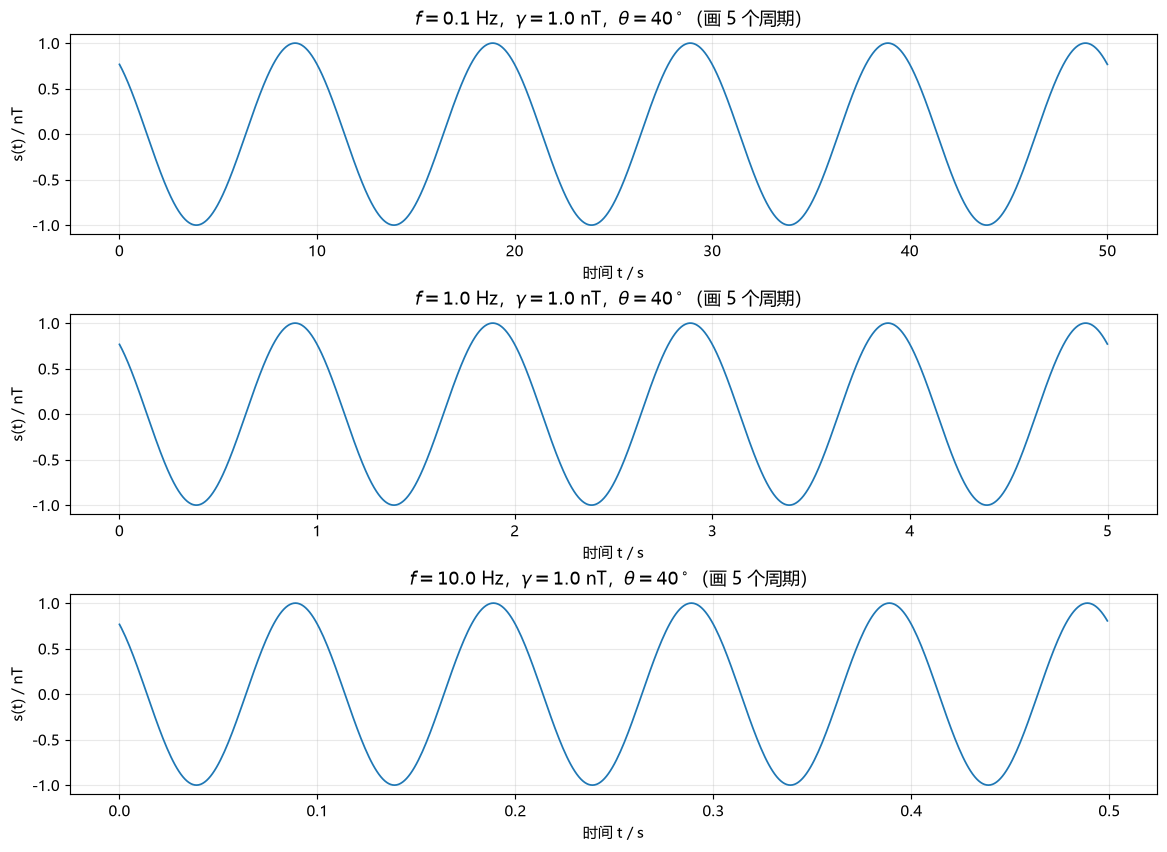

信号均方理论值 γ²/2 = 0.5000 nT²；样本均方 = 0.5000 nT²
目前只有 γ、θ 的「真值」用于造数据；检测时二者都是未知量，见阶段 4–5。


In [3]:
# 三个频点的单频信号：每个画 5 个周期，避免高频点挤成一团
t = np.arange(0.0, T_OBS, 1.0 / FS)
theta = np.deg2rad(THETA_DEG)

fig, axes = plt.subplots(3, 1, figsize=(11, 8), constrained_layout=True)
for ax, f in zip(axes, F_GRID):
    s = GAMMA_NT * np.cos(2 * np.pi * f * t + theta)
    win = t < min(T_OBS, 5.0 / f)          # 各画 5 个周期
    ax.plot(t[win], s[win], lw=1.2)
    ax.set_title(f'$f={f}$ Hz，$\\gamma={GAMMA_NT}$ nT，$\\theta={THETA_DEG:.0f}^\\circ$（画 5 个周期）')
    ax.set_xlabel('时间 t / s')
    ax.set_ylabel('s(t) / nT')
plt.show()

s_main = GAMMA_NT * np.cos(2 * np.pi * F_MAIN * t + theta)
print(f'信号均方理论值 γ²/2 = {GAMMA_NT**2/2:.4f} nT²；样本均方 = {np.mean(s_main**2):.4f} nT²')
print(f'目前只有 γ、θ 的「真值」用于造数据；检测时二者都是未知量，见阶段 4–5。')

## 3. 噪声模型：两档可切换 + 一档待替换

**A 档｜高斯白噪（基线）**：$n\sim\mathcal N(0,\sigma^2)$，每样本独立。与教科书结论对齐，给后续阈值扫描提供干净对照；缺点是会高估算法性能——真实极低频背景不是白的。

**B 档｜$1/f^{\alpha}$ 色噪（主力）**：$S_n(f)\propto f^{-\alpha},\ 0<\alpha<2$，取 0.5 / 1.0 / 1.2 / 1.5 四档（与 ★[3] 仿真设置对齐，便于将来同条件对照）。用频域整形生成：白噪 FFT → 乘 $f^{-\alpha/2}$ → IFFT，**固定随机种子**以便复现；低于 0.03 Hz 的分量置零（300 s 记录本来也分辨不了），否则极低频会独占全部方差。

**C 档｜实测替换（暂缺）**：导师组实测噪声序列到位后，直接当 $H_0$ 样本源。这是把「仿真论文」变成「结合科研」的唯一途径。

> 50 Hz 工频及谐波、脉冲干扰、量化噪声：先留接口，不加。加之前先问「它会不会改变结论」。

In [ ]:
# 频域整形生成 1/f^alpha 噪声；白噪与色噪共用同一底层随机 realization，便于看形状差异
def colored_noise(n, fs, alpha, rng):
    freqs = np.fft.rfftfreq(n, d=1.0 / fs)
    spec = rng.standard_normal(freqs.size) + 1j * rng.standard_normal(freqs.size)
    scale = np.zeros_like(freqs)
    scale[1:] = freqs[1:] ** (-alpha / 2.0)   # PSD ∝ f^{-alpha}  ⇒  幅度谱 ∝ f^{-alpha/2}
    # 低截止：300 s 记录本来也分辨不了 0.03 Hz 以下；不截止会让极低频分量
    # 独占全部方差，Welch 短窗去趋势后功率几乎为零（实测会拟合出 NaN 斜率）。
    scale[f < 0.03] = 0.0
    spec *= scale
    spec[0] = 0.0                              # 去掉直流，避免均值漂移
    x = np.fft.irfft(spec, n=n)
    return x / x.std()                         # 归一化到单位样本方差，σ 由 SNR 统一控制

rng_w = np.random.default_rng(SEED)
n_white = rng_w.standard_normal(t.size)
noises = {a: colored_noise(t.size, FS, a, np.random.default_rng(SEED)) for a in ALPHAS}

# PSD 用全记录周期图 + 对数频率分箱：比 Welch 短窗更能保住低频斜率
freqs = np.fft.rfftfreq(t.size, d=1.0 / FS)
edges = np.logspace(np.log10(0.05), np.log10(50.0), 60)
fbin = np.sqrt(edges[:-1] * edges[1:])

def logbinned_psd(x):
    """全记录 Hann 窗周期图，在 log-f 网格上分箱平均，返回各箱中心与功率。"""
    P = np.abs(np.fft.rfft(x * np.hanning(x.size))) ** 2
    return np.array([P[(freqs >= edges[i]) & (freqs < edges[i + 1])].mean()
                     for i in range(edges.size - 1)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
win = t < 5.0
axes[0].plot(t[win], n_white[win], lw=0.7, alpha=0.75, label='白噪')
axes[0].plot(t[win], noises[1.0][win], lw=0.9, label='$1/f$ 色噪（$\\alpha=1$）')
axes[0].set_xlabel('时间 t / s'); axes[0].set_ylabel('归一化噪声')
axes[0].set_title('时域：白噪 vs 色噪（条件：同种子、5 s 窗口）')
axes[0].legend(fontsize=8)

psds = {}
for a in ALPHAS:
    psds[a] = logbinned_psd(noises[a])
    axes[1].loglog(fbin, psds[a], lw=1.0, label=f'$\\alpha={a}$')
p_at_005 = psds[1.0][0]
axes[1].loglog(fbin, p_at_005 * (fbin / fbin[0]) ** (-1.0),
               'k--', lw=1, alpha=0.5, label='参考斜率 −1')
axes[1].set_xlabel('频率 f / Hz'); axes[1].set_ylabel('PSD（任意单位）')
axes[1].set_title('频域：四条 1/f^α 谱（0.03–500 Hz 带限，300 s / 1 kHz）')
axes[1].legend(fontsize=8)
plt.show()

# 用 log-log 直线拟合核对生成器的实际斜率，避免「画出来像 1/f 就当它是」
slopes = []
for a in ALPHAS:
    slope = np.polyfit(np.log10(fbin), np.log10(psds[a]), 1)[0]
    slopes.append(slope)
    print(f'α={a}: 拟合 PSD 斜率 = {slope:+.3f}（理论 −{a:.1f}，0.05–50 Hz 分箱拟合）')
print('带限说明：低于 0.03 Hz 分量被置零，避免 300 s 记录里极低频独占方差；'
      '拟合偏差约 0.04，来自有限样本与对数分箱。')

## 4. SNR 口径：写死一套，换算一套

**主口径（本课题主线，与 ★[3] 同构）**：整段序列能量比

$$\mathrm{SNR}_E=10\lg\frac{\sum_i s(i)^2}{\sum_i n(i)^2}$$

**对照口径（仅引用 ★[2] 时换算）**：带内信号功率 / 带内噪声功率

$$\mathrm{SNR}_{\rm band}=10\lg\frac{\overline{s^2}}{N_0 B}$$

三套硬规矩：

1. 论文正文只出现**一种主口径**，另一套只作换算说明，绝不混用。
2. 任何 SNR 数字后面必须跟：噪声类型与 $\alpha$、带宽 $B$、采样率、时长 $T$、判据。
3. **不与文献数字横向比较**。★[2] 的 −23/−21 dB 是 0–10 Hz 带限窄带口径；★[3] 的 −15 dB 是整段能量比；噪声模型、带宽、判据全不同。

> **口径自查（本号新发现）**：`阶段1-信号与噪声模型假设.md` §三 A 档把单边谱写成 $N_0=\sigma^2/f_s$。若每样本方差确实是 $\sigma^2$、采样率 $f_s$，严格地说单边谱应为 $2\sigma^2/f_s$（双边谱 $\sigma^2/f_s$ 再乘 2）。本号按严格口径换算，与该简写相差 3 dB；写进论文前建议同步修正文档。
>
> 方法学注脚（A5）：SNR 在 $D\to0$ 时发散，所以「SNR 提升 X dB」不能证明任何事。本课题最终要报的是**固定 $P_{fa}$ 下的 $P_d$**，SNR 增益只作描述性结果。

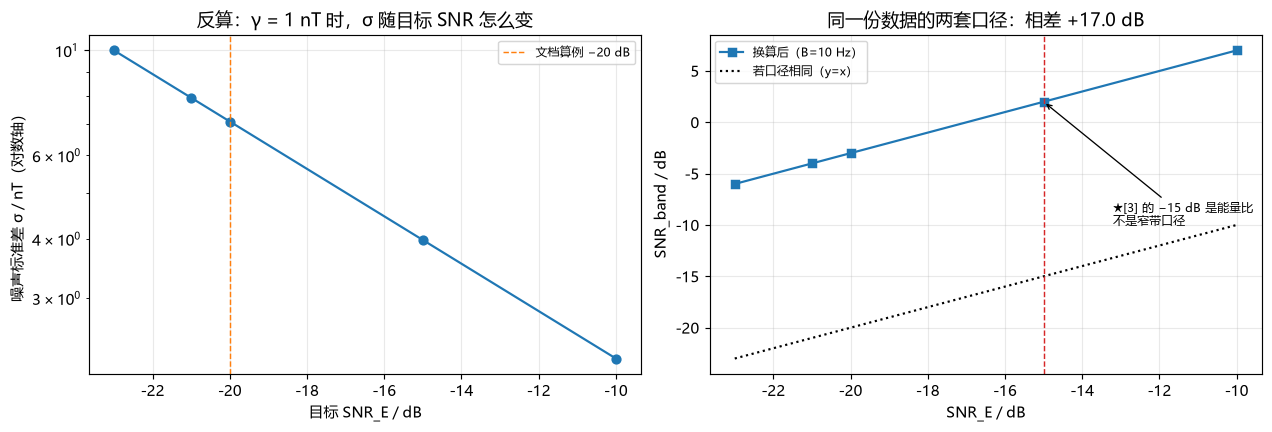

  SNR_E (dB)      σ (nT)   SNR_band (dB)     差值 (dB)
         -23       9.988            -6.0        17.0
         -21       7.934            -4.0        17.0
         -20       7.071            -3.0        17.0
         -15       3.976             2.0        17.0
         -10       2.236             7.0        17.0

换算因子 = 10lg(fs/(2B)) = 10lg(1000/20) = +17.0 dB
（单边谱按 2σ²/fs；若沿用阶段1文档 §三 的简写 σ²/fs，换算因子会是 +20.0 dB，差 3 dB——写论文前需统一。）
解释：能量比用全带宽噪声，窄带口径只算 0–10 Hz；噪声带宽差 50 倍 ⇒ 数字差一大截。
所以 ★[2] 的 −23 dB 与 ★[3] 的 −15 dB 之间不能画等号，也不能说谁更灵敏。
实算校验：γ=1 nT、σ=7.071 nT 的白噪序列 → SNR_E = -20.00 dB（目标 −20 dB）


In [5]:
# 反算表：给定目标 SNR_E，反推 σ（写进代码，不手算）
snr_targets = np.array([-23.0, -21.0, -20.0, -15.0, -10.0])
sigma_nT = np.sqrt((GAMMA_NT**2 / 2.0) / (10 ** (snr_targets / 10.0)))

# 两套口径的换算差：同一份数据，窄带只算 0–B Hz 的噪声功率
delta_db = 10.0 * np.log10(FS / (2.0 * B_BAND))   # 单边带内噪声 N0·B = (2σ²/fs)·B
snr_band = snr_targets + delta_db

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), constrained_layout=True)
axes[0].semilogy(snr_targets, sigma_nT, 'o-')
axes[0].set_xlabel('目标 SNR_E / dB'); axes[0].set_ylabel('噪声标准差 σ / nT（对数轴）')
axes[0].set_title('反算：γ = 1 nT 时，σ 随目标 SNR 怎么变')
axes[0].axvline(-20, color='tab:orange', ls='--', lw=1, label='文档算例 −20 dB')
axes[0].legend(fontsize=8)

axes[1].plot(snr_targets, snr_band, 's-', label=f'换算后（B={B_BAND:g} Hz）')
axes[1].plot(snr_targets, snr_targets, 'k:', label='若口径相同（y=x）')
axes[1].axvline(-15, color='tab:red', ls='--', lw=1)
axes[1].annotate('★[3] 的 −15 dB 是能量比\n不是窄带口径', (-15, snr_band[3]),
                 xytext=(-13.2, snr_band[3] - 12), fontsize=8,
                 arrowprops=dict(arrowstyle='->', lw=0.9))
axes[1].set_xlabel('SNR_E / dB'); axes[1].set_ylabel('SNR_band / dB')
axes[1].set_title(f'同一份数据的两套口径：相差 {delta_db:+.1f} dB')
axes[1].legend(fontsize=8)
plt.show()

print(f"{'SNR_E (dB)':>12}{'σ (nT)':>12}{'SNR_band (dB)':>16}{'差值 (dB)':>12}")
for a, b, c in zip(snr_targets, sigma_nT, snr_band):
    print(f'{a:>12.0f}{b:>12.3f}{c:>16.1f}{c - a:>12.1f}')
print(f'\n换算因子 = 10lg(fs/(2B)) = 10lg({FS:.0f}/{2*B_BAND:.0f}) = {delta_db:+.1f} dB')
print('（单边谱按 2σ²/fs；若沿用阶段1文档 §三 的简写 σ²/fs，换算因子会是 '
      f'{10*np.log10(FS/B_BAND):+.1f} dB，差 3 dB——写论文前需统一。）')
print('解释：能量比用全带宽噪声，窄带口径只算 0–10 Hz；噪声带宽差 50 倍 ⇒ 数字差一大截。')
print('所以 ★[2] 的 −23 dB 与 ★[3] 的 −15 dB 之间不能画等号，也不能说谁更灵敏。')

# 用真实生成的白噪验证反算（能量比口径）
sigma20 = np.sqrt((GAMMA_NT**2 / 2.0) / 10 ** (-20.0 / 10.0))
check_n = sigma20 * np.random.default_rng(SEED + 1).standard_normal(t.size)
snr_meas = 10 * np.log10(np.mean(s_main**2) / np.mean(check_n**2))
print(f'实算校验：γ=1 nT、σ={sigma20:.3f} nT 的白噪序列 → SNR_E = {snr_meas:.2f} dB（目标 −20 dB）')

## 5. $H_0/H_1$：把「有没有信号」写成可计算的形式

| 假设 | 内容 | 数据生成 | 判错意味着什么 |
|---|---|---|---|
| $H_0$ | 仅噪声：$x(t)=n(t)$ | A 档白噪或 B 档色噪；C 档到位后用实测 | 判「有」= 虚警，统计 $P_{fa}$ |
| $H_1$ | 信号 + 噪声：$x(t)=s(t)+n(t)$ | 同上 + $\gamma\cos(\omega t+\theta)$，$\theta$ 在 $[0,2\pi)$ 随机 | 判「有」= 检出，统计 $P_d$ |

两条纪律：① 每次试验独立重抽噪声与 $\theta$，每点 ≥100 次（★[3] 用 100 组，可对齐）；② **阈值由 $H_0$ 样本单独标定，不得用 $H_1$ 数据调阈值**——这是 ROC 是否可信的分水岭。

下面的相干投影只用来演示假设检验框架（有 $H_0$ 对照、有阈值纪律），**不是本课题的检测器**；真正的相变判据阶段 3 才建。

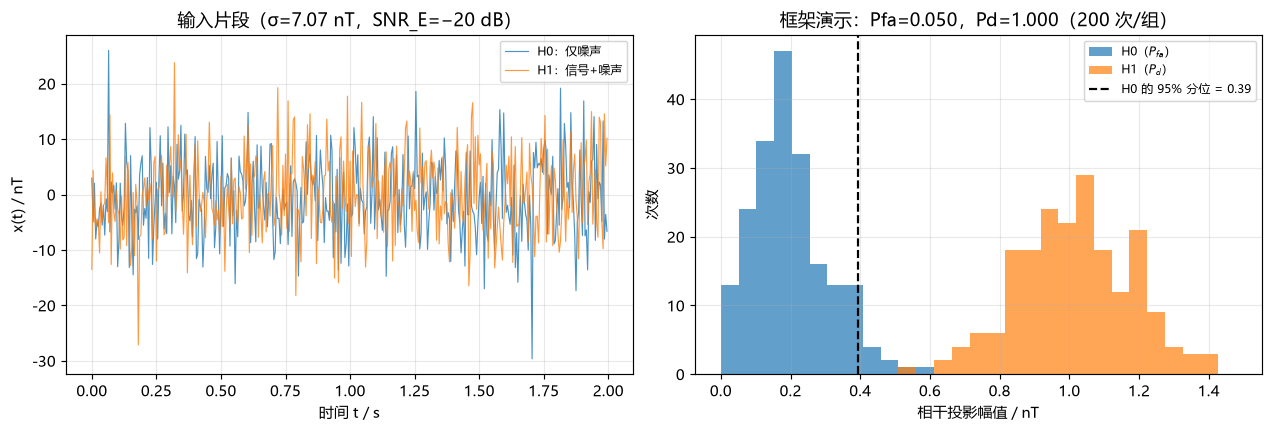

阈值（仅由 H0 标定）= 0.394 nT → Pfa = 0.050，Pd = 1.000
注意：这里 Pd 很高只是因为参考统计量「知道频率」，不是检测器性能的结论。
阶段 4 必须换成 H0 独立标定 + 多 SNR 点 + 100 次以上蒙特卡洛，才允许报门限。


In [6]:
# 演示：200 次独立试验，H0/H1 各一组；统计量为已知频率处的相干投影幅值
rng_h = np.random.default_rng(SEED + 9)
NMC, FS_D, T_D = 200, 200.0, 20.0
tt = np.arange(0.0, T_D, 1.0 / FS_D)
basis_c = np.cos(2 * np.pi * F_MAIN * tt)
basis_s = np.sin(2 * np.pi * F_MAIN * tt)
s_demo = GAMMA_NT * np.cos(2 * np.pi * F_MAIN * tt + theta)

def proj_amp(x):
    """相干投影幅值：2·|mean(x·e^{-iωt})|，对已知频率的正弦无偏。"""
    return 2.0 * np.hypot(np.mean(x * basis_c), np.mean(x * basis_s))

stat_h0 = np.array([proj_amp(sigma20 * rng_h.standard_normal(tt.size)) for _ in range(NMC)])
stat_h1 = np.array([proj_amp(s_demo + sigma20 * rng_h.standard_normal(tt.size)) for _ in range(NMC)])

thr_h0 = np.quantile(stat_h0, 0.95)      # 阈值只看 H0，不看 H1
pd_demo = (stat_h1 > thr_h0).mean()
pfa_demo = (stat_h0 > thr_h0).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), constrained_layout=True)
axes[0].plot(tt[:400], sigma20 * rng_h.standard_normal(400), lw=0.8, alpha=0.8, label='H0：仅噪声')
axes[0].plot(tt[:400], (s_demo + sigma20 * rng_h.standard_normal(tt.size))[:400], lw=0.8,
             alpha=0.8, label='H1：信号+噪声')
axes[0].set_xlabel('时间 t / s'); axes[0].set_ylabel('x(t) / nT')
axes[0].set_title(f'输入片段（σ={sigma20:.2f} nT，SNR_E=−20 dB）')
axes[0].legend(fontsize=8)

bins = np.linspace(0, max(stat_h1.max(), stat_h0.max()) * 1.05, 30)
axes[1].hist(stat_h0, bins=bins, alpha=0.7, label='H0（$P_{fa}$）')
axes[1].hist(stat_h1, bins=bins, alpha=0.7, label='H1（$P_d$）')
axes[1].axvline(thr_h0, color='k', ls='--', label=f'H0 的 95% 分位 = {thr_h0:.2f}')
axes[1].set_xlabel('相干投影幅值 / nT'); axes[1].set_ylabel('次数')
axes[1].set_title(f'框架演示：Pfa={pfa_demo:.3f}，Pd={pd_demo:.3f}（{NMC} 次/组）')
axes[1].legend(fontsize=8)
plt.show()

print(f'阈值（仅由 H0 标定）= {thr_h0:.3f} nT → Pfa = {pfa_demo:.3f}，Pd = {pd_demo:.3f}')
print('注意：这里 Pd 很高只是因为参考统计量「知道频率」，不是检测器性能的结论。')
print('阶段 4 必须换成 H0 独立标定 + 多 SNR 点 + 100 次以上蒙特卡洛，才允许报门限。')

## 6. 研究空白：不是「没人做过」，是「只交了一半指标」

[阶段1-问题清单.md](../01-阶段一/阶段1-问题清单.md) 共 12 条，其中 5 条标 ★ 是**论文没回答的**：

| # | 空白 | 谁留下的 | 本课题怎么补 |
|---|---|---|---|
| Q1 | 只有 $P_d$，无 $P_{fa}$ | ★[3] | 给 $P_d$–$P_{fa}$–SNR 曲面 |
| Q2 | 峰峰值噪声 ≠ 谱密度 | E3 | 补测 PSD，或明确不比较 |
| Q3 | 静态标定，无温漂/动态 | E1 | 温循试验，或在局限中声明 |
| Q4 | SNR 指标本身会骗人 | A5 | 主指标改为固定 $P_{fa}$ 的 $P_d$ |
| Q5 | 全领域无统一 ROC | D1（2021 综述） | 先查 2021 后文献，再决定是否作创新点 |

> 这五条合起来就是开题报告「研究空白」的骨架。注意措辞：**不是「没人做过混沌检测」（这句站不住），而是「做过的人都只交了一半的指标」**。

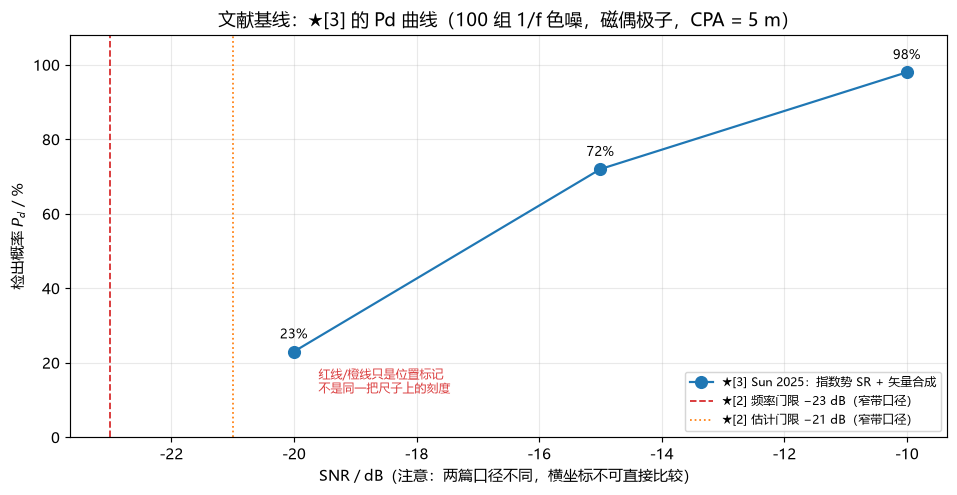

Q1｜只有 Pd，无 Pfa（★[3] 留下）
Q2｜峰峰值噪声 ≠ 谱密度（E3 留下）
Q3｜静态标定，无温漂/动态（E1 留下）
Q4｜SNR 指标本身会骗人（A5 留下）
Q5｜全领域无统一 ROC（D1 留下）


In [7]:
# 最近对手的基线：三个点，全部带条件；★[2] 的门限只作位置示意，口径不同不可并列
snr_lit = np.array([-20.0, -15.0, -10.0])
pd_lit = np.array([0.23, 0.72, 0.98])

fig, ax = plt.subplots(figsize=(9, 4.6), constrained_layout=True)
ax.plot(snr_lit, pd_lit * 100, 'o-', ms=8, color='tab:blue',
        label='★[3] Sun 2025：指数势 SR + 矢量合成')
for x, y in zip(snr_lit, pd_lit):
    ax.annotate(f'{y*100:.0f}%', (x, y * 100), xytext=(0, 9),
                textcoords='offset points', ha='center', fontsize=9)
ax.axvline(-23, color='tab:red', ls='--', lw=1.2, label='★[2] 频率门限 −23 dB（窄带口径）')
ax.axvline(-21, color='tab:orange', ls=':', lw=1.2, label='★[2] 估计门限 −21 dB（窄带口径）')
ax.set_xlabel('SNR / dB（注意：两篇口径不同，横坐标不可直接比较）')
ax.set_ylabel('检出概率 $P_d$ / %')
ax.set_title('文献基线：★[3] 的 Pd 曲线（100 组 1/f 色噪，磁偶极子，CPA = 5 m）')
ax.set_ylim(0, 108)
ax.legend(fontsize=8, loc='lower right')
ax.text(-19.6, 12, '红线/橙线只是位置标记\n不是同一把尺子上的刻度',
        fontsize=8, color='tab:red', alpha=0.9)
plt.show()

for q, gap, who in [
    ('Q1', '只有 Pd，无 Pfa', '★[3]'), ('Q2', '峰峰值噪声 ≠ 谱密度', 'E3'),
    ('Q3', '静态标定，无温漂/动态', 'E1'), ('Q4', 'SNR 指标本身会骗人', 'A5'),
    ('Q5', '全领域无统一 ROC', 'D1')]:
    print(f'{q}｜{gap}（{who} 留下）')

## 7. 阶段 1 交出什么 / 不交什么

**交出**（对应五件产物 + 本 notebook）：① 现状综述草稿（1110 字，四段结构）；② 信号与噪声模型假设（$s(t)$、两档噪声、参数表、SNR 主口径、$H_0/H_1$）；③ 5 张文献卡片；④ E1/E3 获取记录（全文已入库）；⑤ 12 条问题清单（5 条论文没答）。本 notebook 把其中**能算的部分**实跑了一遍：三频点信号、四条 $1/f^\alpha$ 谱、SNR 反算与双口径换算、$H_0/H_1$ 阈值纪律、文献基线。

**不交**：Duffing 方程、RK4、相图、$\lambda_c$、参数估计公式、ROC 与门限数值、FPGA 资源评估。一旦开始跑这些，就计入阶段 2 以后。

**待导师补齐四件事**：① 实测背景噪声（替换 C 档）；② 目标真实频段与幅值量级；③ 前端传感器型号与噪声底；④ 验收指标形式（$P_d$@固定 $P_{fa}$ 还是误差棒）。

> 下一站的入口：拿本号的信号/噪声模型当输入，进 `learn/0.ipynb` 第 1 节开始阶段 2 的建模。

In [8]:
# 结果落盘：只存阶段 1 的条件化数字，便于写开题报告时直接引用
summary = {
    'stage': 1,
    'signal_model': {
        'form': 's(t) = gamma*cos(2*pi*f*t + theta)',
        'gamma_nT': GAMMA_NT, 'freq_grid_Hz': list(F_GRID),
        'theta_deg_assumed': THETA_DEG,
        'known': ['frequency (or band)'], 'unknown': ['gamma', 'theta'],
    },
    'noise_models': {
        'A_white': 'n ~ N(0, sigma^2), per-sample',
        'B_colored': {'psd': 'f^(-alpha)', 'alphas': list(ALPHAS),
                      'fitted_slopes': [round(float(v), 3) for v in slopes]},
        'C_measured': 'PENDING — replace with导师实测序列',
    },
    'conditions': {'fs_Hz': FS, 'T_s': T_OBS, 'B_Hz': B_BAND,
                   'seed': SEED, 'snr_main_def': 'SNR_E = 10lg(sum s^2 / sum n^2)'},
    'snr_reverse': [
        {'SNR_E_dB': float(a), 'sigma_nT': round(float(b), 4),
         'SNR_band_dB': round(float(c), 1)}
        for a, b, c in zip(snr_targets, sigma_nT, snr_band)
    ],
    'hypothesis_demo': {'method': 'coherent projection (framework demo, NOT the detector)',
                        'NMC': NMC, 'threshold_from_H0_percentile': 95,
                        'Pfa': round(float(pfa_demo), 3), 'Pd': round(float(pd_demo), 3)},
    'literature_baseline': {'source': 'Sun 2025 IEEE Sensors J, 100 runs, 1/f noise, CPA=5m',
                            'SNR_dB': list(snr_lit), 'Pd': list(pd_lit)},
    'gaps': ['Q1 只有Pd无Pfa', 'Q2 峰峰值≠谱密度', 'Q3 静态标定无温漂',
             'Q4 SNR指标会骗人', 'Q5 全领域无统一ROC'],
}
path = OUT / '阶段1-信号噪声与口径汇总.json'
path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'已写入：{path}')
print(f'阶段 1 notebook 全部完成，耗时 {time.time() - _START:.1f} s')

已写入：C:\Users\22902\WorkBuddy\毕设\复现输出\阶段1-信号噪声与口径汇总.json
阶段 1 notebook 全部完成，耗时 1156.3 s
